# FA2 Case Study: Data Analysis Using Machine Learning & Streamlit Deployment
**Problem:** Predict whether a Titanic passenger survived (binary classification).
**Dataset:** Titanic - Machine Learning from Disaster (Kaggle), file `train.csv`, 891 rows.
**Models:** Logistic Regression, Decision Tree, Random Forest, SVM, k-NN.

## Part 1: Data Acquisition & Preprocessing

### 1.1 Imports

In [3]:

import warnings
warnings.filterwarnings("ignore")

import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report, ConfusionMatrixDisplay)

### 1.2 Dataset Selection
The Titanic dataset (Kaggle) has passenger details (class, sex, age, family size, fare, port of embarkation).
The goal is to predict `Survived` (0 = No, 1 = Yes). It suits this case study because it is a classification problem
with missing values and categorical columns, so every preprocessing step is exercised.

### 1.3 Data Loading

In [4]:
df = pd.read_csv("train.csv")   # keep train.csv in the same folder as this notebook
print("Shape:", df.shape)
df.head()

Shape: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


### 1.4 Exploratory Data Analysis (EDA)

In [5]:
df.info()
print()
print("Missing values per column:")
print(df.isnull().sum())
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 118.9 KB

Missing values per column:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dt

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


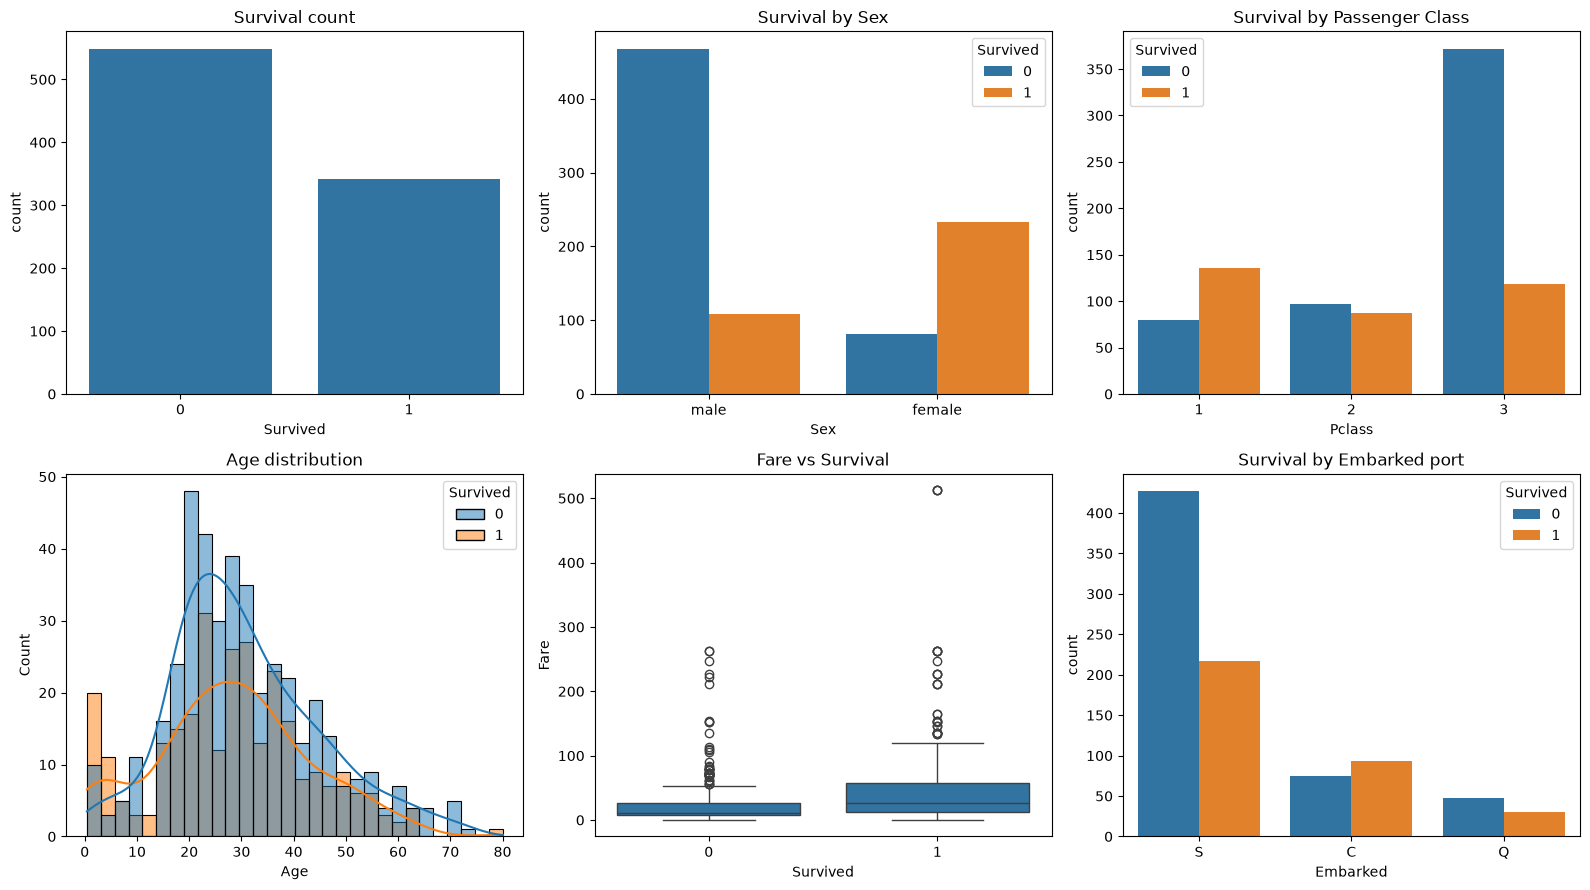

In [6]:
# Target distribution and survival by key features
fig, ax = plt.subplots(2, 3, figsize=(16, 9))

sns.countplot(x="Survived", data=df, ax=ax[0, 0]);            ax[0, 0].set_title("Survival count")
sns.countplot(x="Sex", hue="Survived", data=df, ax=ax[0, 1]);  ax[0, 1].set_title("Survival by Sex")
sns.countplot(x="Pclass", hue="Survived", data=df, ax=ax[0, 2]); ax[0, 2].set_title("Survival by Passenger Class")
sns.histplot(data=df, x="Age", hue="Survived", bins=30, kde=True, ax=ax[1, 0]); ax[1, 0].set_title("Age distribution")
sns.boxplot(x="Survived", y="Fare", data=df, ax=ax[1, 1]);     ax[1, 1].set_title("Fare vs Survival")
sns.countplot(x="Embarked", hue="Survived", data=df, ax=ax[1, 2]); ax[1, 2].set_title("Survival by Embarked port")
plt.tight_layout(); plt.show()

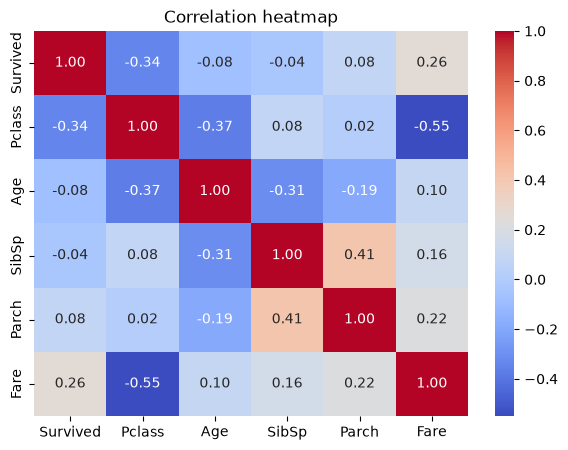

In [7]:
# Correlation between numeric features
plt.figure(figsize=(7, 5))
sns.heatmap(df[["Survived", "Pclass", "Age", "SibSp", "Parch", "Fare"]].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation heatmap"); plt.show()

### 1.5 EDA Findings
- Females survived far more often than males.
- Higher class (Pclass 1) passengers survived more; Pclass 3 had the lowest survival.
- `Age` has missing values, `Cabin` is mostly missing, and `Embarked` has very few missing values.
- Fare is right-skewed; passengers who paid higher fares survived more often.
- Challenges: missing data, categorical columns, and features on very different scales.

### 1.6 Data Preprocessing

In [8]:
# (a) Drop columns that are identifiers or too sparse to be useful
df = df.drop(columns=["PassengerId", "Name", "Ticket", "Cabin"])

# (b) Handle missing values
df["Age"] = df["Age"].fillna(df["Age"].median())            # numeric -> median
df["Embarked"] = df["Embarked"].fillna(df["Embarked"].mode()[0])  # categorical -> mode
print("Missing values left:", df.isnull().sum().sum())

Missing values left: 0


In [9]:
# (c) Encode categorical features
df["Sex"] = df["Sex"].map({"male": 0, "female": 1})          # label encoding
df = pd.get_dummies(df, columns=["Embarked"], drop_first=True)  # one-hot encoding
df = df.astype({c: int for c in df.columns if df[c].dtype == bool})
df.head()

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked_Q,Embarked_S
0,0,3,0,22.0,1,0,7.2500,0,1
1,1,1,1,38.0,1,0,71.2833,0,0
2,1,3,1,26.0,0,0,7.9250,0,1
3,1,1,1,35.0,1,0,53.1000,0,1
4,0,3,0,35.0,0,0,8.0500,0,1


In [10]:
# (d) Split features / target, then Train/Test split (80/20)
X = df.drop(columns=["Survived"])
y = df["Survived"]
feature_columns = list(X.columns)
print("Features:", feature_columns)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
print("Train:", X_train.shape, " Test:", X_test.shape)

# (e) Feature scaling (fit ONLY on training data to avoid data leakage)
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

Features: ['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked_Q', 'Embarked_S']
Train: (712, 8)  Test: (179, 8)


## Part 2: Model Implementation & Evaluation

In [11]:
# Model implementation using scikit-learn
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Decision Tree":       DecisionTreeClassifier(max_depth=5, random_state=42),
    "Random Forest":       RandomForestClassifier(n_estimators=100, random_state=42),
    "SVM":                 SVC(kernel="rbf", probability=True, random_state=42),
    "k-NN":                KNeighborsClassifier(n_neighbors=5),
}

# Model training
for name, model in models.items():
    model.fit(X_train_s, y_train)
    print(f"Trained: {name}")

Trained: Logistic Regression
Trained: Decision Tree
Trained: Random Forest
Trained: SVM
Trained: k-NN


Logistic Regression
              precision    recall  f1-score   support

        Died       0.81      0.89      0.85       110
    Survived       0.79      0.67      0.72        69

    accuracy                           0.80       179
   macro avg       0.80      0.78      0.79       179
weighted avg       0.80      0.80      0.80       179

Decision Tree
              precision    recall  f1-score   support

        Died       0.79      0.87      0.83       110
    Survived       0.75      0.62      0.68        69

    accuracy                           0.78       179
   macro avg       0.77      0.75      0.76       179
weighted avg       0.77      0.78      0.77       179

Random Forest
              precision    recall  f1-score   support

        Died       0.82      0.88      0.85       110
    Survived       0.78      0.68      0.73        69

    accuracy                           0.80       179
   macro avg       0.80      0.78      0.79       179
weighted avg       0.80   

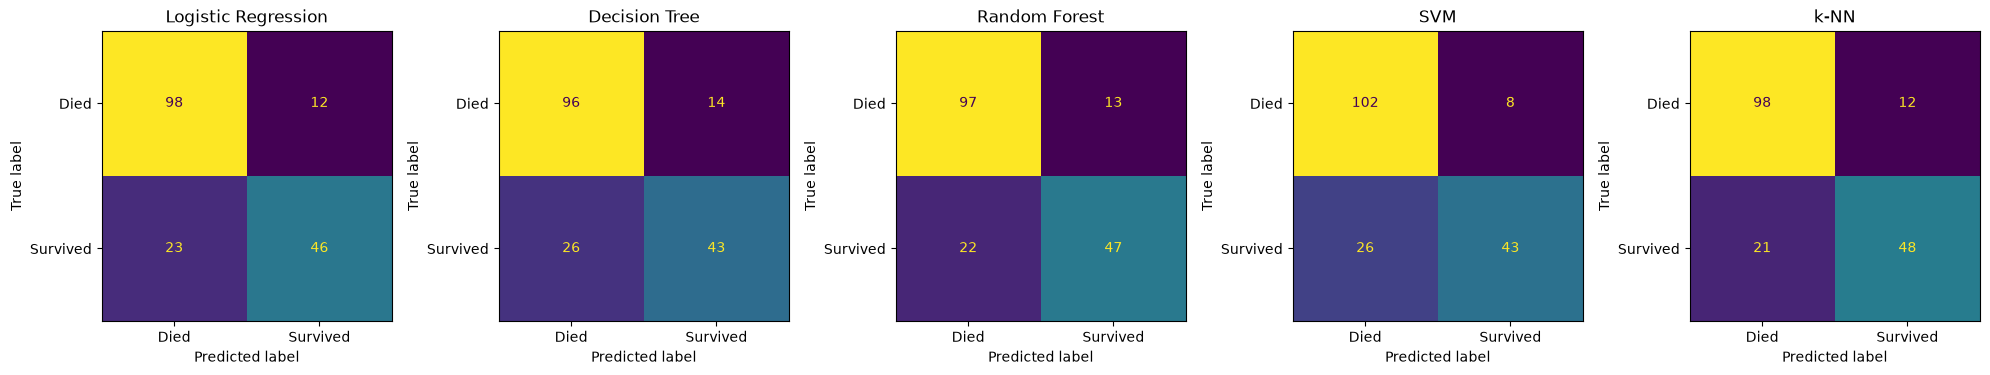

,Accuracy,Precision,Recall,F1-score
Model,,,,
Logistic Regression,0.8045,0.7931,0.6667,0.7244
Decision Tree,0.7765,0.7544,0.6232,0.6825
Random Forest,0.8045,0.7833,0.6812,0.7287
SVM,0.8101,0.8431,0.6232,0.7167
k-NN,0.8156,0.8000,0.6957,0.7442


In [12]:
# Model evaluation: metrics, confusion matrix and classification report for each model
results = []
fig, axes = plt.subplots(1, len(models), figsize=(20, 4))

for ax, (name, model) in zip(axes, models.items()):
    pred = model.predict(X_test_s)
    results.append({
        "Model": name,
        "Accuracy":  accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall":    recall_score(y_test, pred),
        "F1-score":  f1_score(y_test, pred),
    })
    print("=" * 55); print(name); print("=" * 55)
    print(classification_report(y_test, pred, target_names=["Died", "Survived"]))
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=["Died", "Survived"]).plot(ax=ax, colorbar=False)
    ax.set_title(name)

plt.tight_layout(); plt.show()

results_df = pd.DataFrame(results).set_index("Model").round(4)
results_df

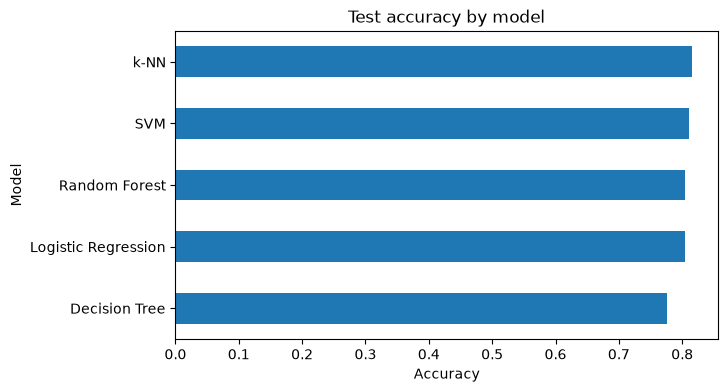

In [13]:
results_df["Accuracy"].sort_values().plot(kind="barh", figsize=(7, 4), title="Test accuracy by model")
plt.xlabel("Accuracy"); plt.show()

### Hyperparameter Tuning (GridSearchCV) & K-Fold Cross-Validation

In [14]:
# GridSearchCV on Random Forest (5-fold)
param_grid = {
    "n_estimators": [100, 200, 300],
    "max_depth": [3, 5, 7, None],
    "min_samples_split": [2, 5, 10],
}
grid = GridSearchCV(RandomForestClassifier(random_state=42), param_grid,
                    cv=5, scoring="accuracy", n_jobs=-1)
grid.fit(X_train_s, y_train)

print("Best parameters   :", grid.best_params_)
print("Best CV accuracy  :", round(grid.best_score_, 4))

best_rf = grid.best_estimator_
tuned_pred = best_rf.predict(X_test_s)
base_acc = accuracy_score(y_test, models["Random Forest"].predict(X_test_s))
print("Test accuracy before tuning:", round(base_acc, 4))
print("Test accuracy after tuning :", round(accuracy_score(y_test, tuned_pred), 4))

Best parameters   : {'max_depth': 7, 'min_samples_split': 10, 'n_estimators': 300}
Best CV accuracy  : 0.8288
Test accuracy before tuning: 0.8045
Test accuracy after tuning : 0.7933


In [15]:
# Stratified 5-Fold cross-validation for ALL models (stability check)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_rows = []
for name, model in models.items():
    scores = cross_val_score(model, X_train_s, y_train, cv=skf, scoring="accuracy")
    cv_rows.append({"Model": name, "Mean CV Accuracy": scores.mean(), "Std": scores.std()})
cv_df = pd.DataFrame(cv_rows).set_index("Model").round(4)
cv_df

,Mean CV Accuracy,Std
Model,,
Logistic Regression,0.7921,0.0255
Decision Tree,0.8048,0.0051
Random Forest,0.8075,0.0224
SVM,0.8230,0.0250
k-NN,0.8048,0.0128


In [17]:
best = results_df["Accuracy"].idxmax()
best_acc = results_df.loc[best, "Accuracy"]
best_f1 = results_df.loc[best, "F1-score"]

tuned_acc = accuracy_score(y_test, tuned_pred)
change = tuned_acc - base_acc
if change > 0:
    outcome = "improved"
elif change < 0:
    outcome = "dropped"
else:
    outcome = "stayed the same"

top_cv = cv_df["Mean CV Accuracy"].idxmax()
stable = cv_df["Std"].idxmin()
lowest_cv = cv_df["Mean CV Accuracy"].idxmin()

print("### Results Summary")
print(f"- Best model on the test set: {best}, with accuracy {best_acc:.4f} and F1-score {best_f1:.4f}.")
print(f"- GridSearchCV on Random Forest gave best parameters {grid.best_params_} with a best CV accuracy of {grid.best_score_:.4f}. "
      f"Test accuracy {outcome} from {base_acc:.4f} (before tuning) to {tuned_acc:.4f} (after tuning).")
print(f"- In 5-fold cross-validation, {top_cv} had the highest mean accuracy ({cv_df.loc[top_cv, 'Mean CV Accuracy']:.4f}), "
      f"while {stable} was the most stable model with the lowest standard deviation ({cv_df.loc[stable, 'Std']:.4f}).")
print(f"- {lowest_cv} had the lowest mean CV accuracy ({cv_df.loc[lowest_cv, 'Mean CV Accuracy']:.4f}).")

### Results Summary
- Best model on the test set: k-NN, with accuracy 0.8156 and F1-score 0.7442.
- GridSearchCV on Random Forest gave best parameters {'max_depth': 7, 'min_samples_split': 10, 'n_estimators': 300} with a best CV accuracy of 0.8288. Test accuracy dropped from 0.8045 (before tuning) to 0.7933 (after tuning).
- In 5-fold cross-validation, SVM had the highest mean accuracy (0.8230), while Decision Tree was the most stable model with the lowest standard deviation (0.0051).
- Logistic Regression had the lowest mean CV accuracy (0.7921).


### Results Summary
Fill in after running: which model had the best test accuracy / F1, how much GridSearchCV improved Random Forest,
and which model was the most stable in cross-validation (lowest std).

## Saving models for Streamlit (joblib)

In [16]:
os.makedirs("models", exist_ok=True)
files = {
    "Logistic Regression": "logistic_regression.joblib",
    "Decision Tree": "decision_tree.joblib",
    "Random Forest": "random_forest.joblib",
    "SVM": "svm.joblib",
    "k-NN": "knn.joblib",
}
for name, fname in files.items():
    joblib.dump(models[name], f"models/{fname}")

joblib.dump(best_rf, "models/random_forest_tuned.joblib")   # tuned model from GridSearchCV
joblib.dump(scaler, "models/scaler.joblib")
joblib.dump(feature_columns, "models/feature_columns.joblib")
print(sorted(os.listdir("models")))

['decision_tree.joblib', 'feature_columns.joblib', 'knn.joblib', 'logistic_regression.joblib', 'random_forest.joblib', 'random_forest_tuned.joblib', 'scaler.joblib', 'svm.joblib']
